## **SPOTIFY TRACK ANALYSIS**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
%matplotlib widget
from mpl_toolkits import mplot3d

In [2]:
df = pd.read_csv("spotify_enhanced.csv")
print("Shape:" , df.shape)

Shape: (114000, 27)


In [3]:
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,tempo,time_signature,track_genre,total_streams,monthly_listeners,songs_500M_plus,number_of_hit_songs,country,likes,shares
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,...,87.917,4,acoustic,80000000,3000000,1,8,UK,100000,10000
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,...,77.489,4,acoustic,3500000000,100000000,4,80,Japan,75000000,8000000
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,...,76.332,4,acoustic,80000000,3000000,4,8,UK,100000,10000
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,...,181.740,3,acoustic,800000000,35000000,3,28,Spain,10000000,1000000
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,...,119.949,4,acoustic,3500000000,100000000,3,80,Japan,75000000,8000000


In [4]:
print(df.dtypes.value_counts().to_dict())
df.info()

{dtype('int64'): 11, dtype('float64'): 9, <StringDtype(storage='python', na_value=nan)>: 6, dtype('bool'): 1}
<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   track_id             114000 non-null  str    
 1   artists              113999 non-null  str    
 2   album_name           113999 non-null  str    
 3   track_name           113999 non-null  str    
 4   popularity           114000 non-null  int64  
 5   duration_ms          114000 non-null  int64  
 6   explicit             114000 non-null  bool   
 7   danceability         114000 non-null  float64
 8   energy               114000 non-null  float64
 9   key                  114000 non-null  int64  
 10  loudness             114000 non-null  float64
 11  mode                 114000 non-null  int64  
 12  speechiness          114000 non-null  float64
 13  acousticness        

In [5]:
missing = df.isnull().sum()

missing_report = pd.DataFrame({
    'Missing Value': missing, 
    'Percentage': (missing / len(df) * 100).round(2)
})
missing_report = missing_report[missing_report['Missing Value'] > 0]

missing_report = missing_report.sort_values(
    by = 'Missing Value', 
    ascending = False)

print("Coloumns with Missing Value:" , len(missing_report))
missing_report

Coloumns with Missing Value: 3


,Missing Value,Percentage
artists,1,0.0
album_name,1,0.0
track_name,1,0.0


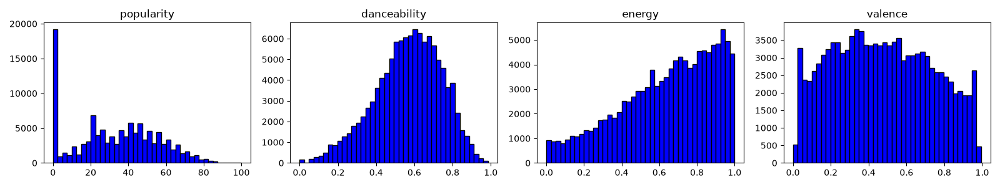

,popularity,danceability,energy,valence
count,114000.00,114000.00,114000.00,114000.00
mean,33.24,0.57,0.64,0.47
std,22.31,0.17,0.25,0.26
min,0.00,0.00,0.00,0.00
25%,17.00,0.46,0.47,0.26
50%,35.00,0.58,0.68,0.46
75%,50.00,0.70,0.85,0.68
max,100.00,0.98,1.00,1.00


In [6]:
num = ['popularity' , 'danceability' , 'energy' , 'valence']
num = [c for c in num if c in df.columns]
fid, ax = plt.subplots(1, len(num) , figsize = (4*len(num) , 3))
ax = np.atleast_1d(ax)
for a , c in zip(ax , num):
    a.hist(df[c].dropna() , bins = 40 , color = 'blue' , edgecolor = 'black'); a.set_title(c)
plt.tight_layout()
plt.show()
df[num].describe().round(2)

## Artists vs Total Streams

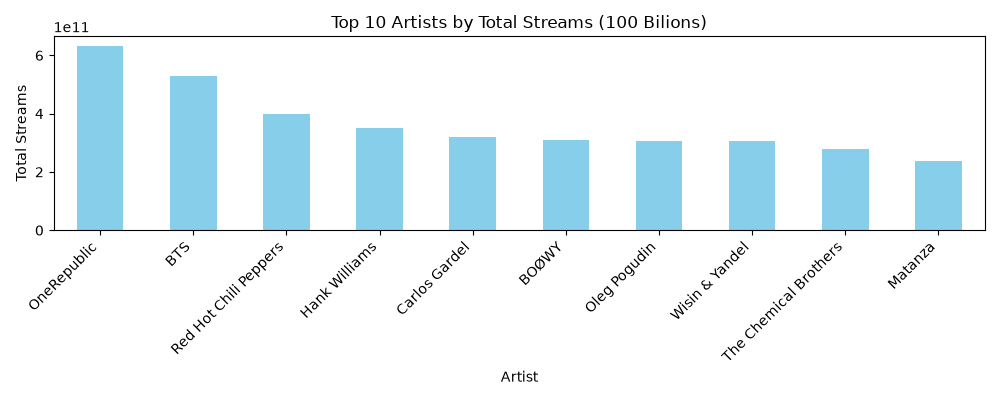

In [7]:
artist = df.groupby('artists')['total_streams'].sum()

artist = artist.sort_values(ascending=False)

artist = artist.head(10)

fig, ax = plt.subplots(figsize=(10,4))

artist.plot(
    kind='bar',
    color='skyblue',
    ax=ax
)

ax.set_title('Top 10 Artists by Total Streams (100 Bilions)')
ax.set_xlabel('Artist')
ax.set_ylabel('Total Streams')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()

plt.show()

## Monthly Listener and Number of Hit Songs

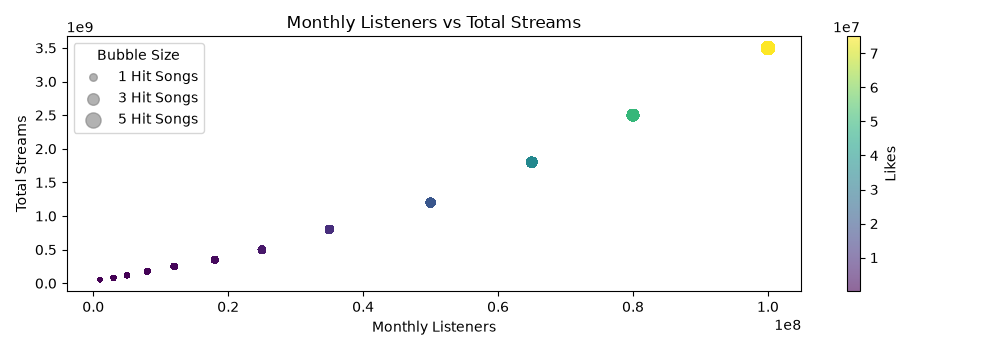

In [8]:
bubble = df[['monthly_listeners' , 
            'total_streams' , 
            'number_of_hit_songs' , 
            'likes']]

bubble = bubble.dropna()

fig, ax = plt.subplots(figsize = (10 , 3.5))

scatter = ax.scatter(
    bubble['monthly_listeners'] , 
    bubble['total_streams'] , 
    s= bubble['number_of_hit_songs'] , 
    c = bubble['likes'] ,
    cmap = 'viridis' ,
    alpha = 0.6
)
ax.set_title("Monthly Listeners vs Total Streams")
ax.set_xlabel("Monthly Listeners")
ax.set_ylabel('Total Streams')

plt.colorbar(scatter , label = 'Likes')

ax.scatter([] , [] , s = 30 , color = 'gray' , alpha = 0.6 , label = '1 Hit Songs')
ax.scatter([] , [] , s = 70 , color = 'gray' , alpha = 0.6 , label = '3 Hit Songs')
ax.scatter([] , [] , s = 120 , color = 'gray' , alpha = 0.6 , label = '5 Hit Songs')

ax.legend(title = "Bubble Size")

plt.tight_layout()
plt.show()

## Top Genre

In [9]:
top_genre = df['track_genre'].value_counts().head(10)
print(top_genre)

track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
anime          1000
black-metal    1000
bluegrass      1000
blues          1000
brazil         1000
Name: count, dtype: int64


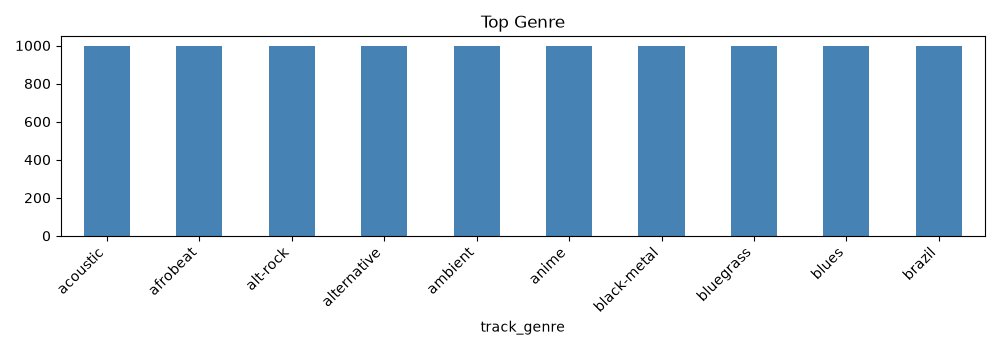

In [10]:
fig, ax = plt.subplots(figsize = (10 , 3.5))
top_genre.plot(
    kind = 'bar',
    ax = ax, 
    color = 'steelblue'
)
ax.set_title('Top Genre')
plt.xticks(rotation = 45 , ha = 'right')

plt.tight_layout()
plt.show()

## Popularity Distribution Across Genres

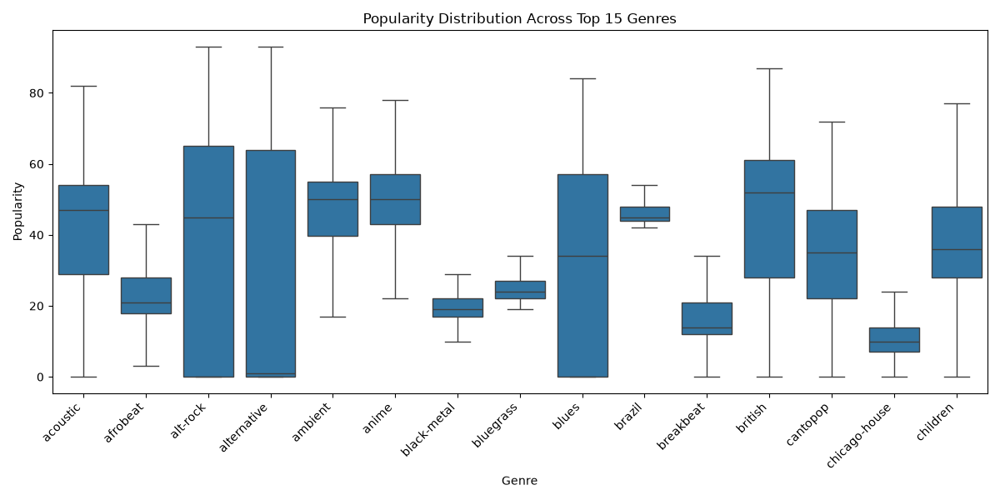

In [11]:
top_genre = df['track_genre'].value_counts().head(15).index
genre_df = df[df['track_genre'].isin(top_genre)]

fig, ax = plt.subplots(figsize = (12 ,6))

sns.boxplot(
    data = genre_df, 
    x = 'track_genre', 
    y = 'popularity',
    showfliers = False,
    ax = ax
)

ax.set_title("Popularity Distribution Across Top 15 Genres")
ax.set_xlabel("Genre")
ax.set_ylabel("Popularity")

plt.xticks(rotation = 45 , ha = 'right')

plt.tight_layout()
plt.show()

## Correlation Heatmap

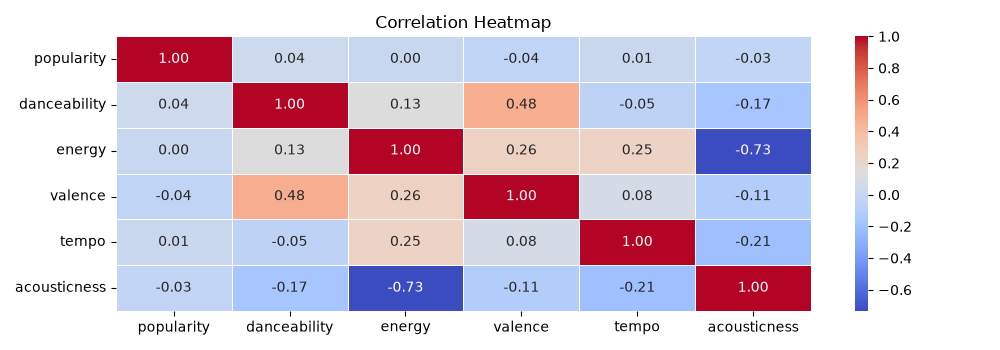

In [12]:
columns = [
    'popularity', 
    'danceability',
    'energy',
    'valence',
    'tempo',
    'acousticness'
]

corr = df[columns].corr()

fig, ax = plt.subplots(figsize = (10 , 3.5))

sns.heatmap(
    corr,
    annot = True,
    fmt = '.2f',
    cmap = 'coolwarm',
    linewidths = 0.5,
    ax = ax
)

ax.set_title('Correlation Heatmap')
plt.tight_layout()
plt.show()

## Countries by Total Streams

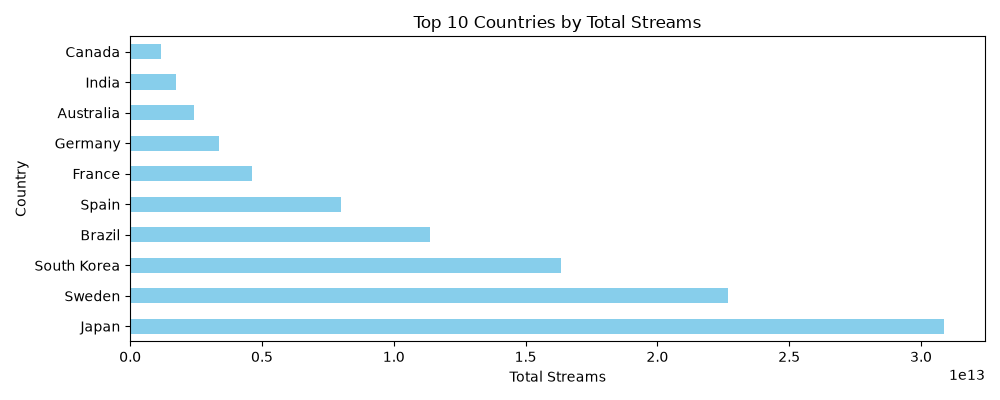

In [13]:
top_country = df.groupby('country')['total_streams'].sum()

top_country = top_country.sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10,4))

top_country.plot(
    kind='barh',
    color='skyblue',
    ax=ax
)

ax.set_title('Top 10 Countries by Total Streams')
ax.set_xlabel('Total Streams')
ax.set_ylabel('Country')

plt.tight_layout()
plt.show()

## 3D Interactive Graph

In [14]:
import plotly.express as px

fig = px.scatter_3d(
    df,
    x='monthly_listeners',
    y='total_streams',
    z='popularity',
    color='country',
    size='number_of_hit_songs',
    hover_name='artists',
    hover_data=[
        'track_name',
        'likes',
        'shares'
    ],
    title='Artist Performance Analysis'
)

fig.update_layout(
    width=900,
    height=650
)

fig.show()